# 03. Data Quality & Relational Integrity Analysis

## 3.1 Pendahuluan

Tahap ini bertujuan untuk mengevaluasi kualitas data dan integritas relasional dari sembilan tabel yang terdapat pada dataset kompetisi Datavidia 11.0 Task 1.

Pemeriksaan dilakukan untuk memastikan bahwa setiap tabel memiliki struktur yang valid, identifier yang konsisten, serta hubungan antarentitas yang dapat digunakan dalam proses integrasi data.

Analisis mencakup:

1. Validasi primary key.
2. Identifikasi duplikasi record.
3. Validasi foreign key.
4. Deteksi orphan records.
5. Analisis hubungan one-to-many.
6. Distribusi frekuensi transaksi per shipment.
7. Analisis pola missing values.
8. Penyusunan temuan kualitas data.

Hasil tahap ini akan digunakan sebagai dasar untuk menentukan strategi pembersihan data, integrasi tabel, dan feature engineering.

## 3.2 Konfigurasi Analisis

Seluruh pemeriksaan dilakukan secara terpisah pada dataset training dan testing untuk memastikan konsistensi integritas data pada kedua bagian.

In [33]:
import sys
!{sys.executable} -m pip install pyarrow

In [34]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path(os.getenv("DATA_DIR", "data"))

SPLITS = ["train", "test"]

TABLES = [
    "shipments",
    "scan_events",
    "route_segments",
    "invoices",
    "customers",
    "couriers",
    "hubs",
    "service_packages",
    "promotions"
]

OPERATIONAL_TABLES = [
    "scan_events",
    "route_segments",
    "invoices"
]

OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def read_table(split, table, columns=None):
    DATA_DIR = Path(r"c:\Users\ASUS\.vscode\arkavidia\data\Task-1-Datavidia-11.0")
    path = DATA_DIR / split / f"{table}.csv"

    return pl.read_csv(
        path,
        columns=columns,
        infer_schema_length=20000
    )

print("Data directory:", DATA_DIR.resolve())
print("Total tables:", len(TABLES))
print("Available splits:", SPLITS)

Data directory: C:\Users\ASUS\.vscode\arkavidia\data
Total tables: 9
Available splits: ['train', 'test']


## 3.1 Primary Key Validation

Primary key merupakan atribut yang digunakan untuk mengidentifikasi setiap record secara unik dalam suatu tabel.

Validasi dilakukan dengan membandingkan jumlah record dengan jumlah nilai identifier unik secara eksak.

Kriteria validasi meliputi:

- Tidak terdapat nilai identifier yang kosong.
- Tidak terdapat identifier yang digunakan oleh lebih dari satu record.
- Jumlah identifier unik sama dengan jumlah record.

Pada tabel operasional, pemeriksaan juga dilakukan terhadap kandidat composite key untuk mengetahui apakah kombinasi beberapa kolom dapat mengidentifikasi record secara unik.

Tahap ini penting untuk menghindari ketidakakuratan dalam proses penggabungan data.

In [35]:
PRIMARY_KEY_CANDIDATES = {
    "shipments": [
        ["shipment_id"]
    ],
    "scan_events": [
        ["event_id"]
    ],
    "route_segments": [
        ["segment_id"],
        ["shipment_id", "urutan"]
    ],
    "invoices": [
        ["invoice_id"]
    ],
    "customers": [
        ["customer_id"]
    ],
    "couriers": [
        ["courier_id"]
    ],
    "hubs": [
        ["hub_id"]
    ],
    "service_packages": [
        ["package_id"]
    ],
    "promotions": [
        ["promo_id"]
    ]
}

pk_records = []

for split in SPLITS:
    for table, candidates in PRIMARY_KEY_CANDIDATES.items():

        for key_columns in candidates:

            df = read_table(
                split,
                table,
                key_columns
            )

            total_rows = df.height

            complete_records = df.filter(
                pl.all_horizontal([
                    pl.col(c).is_not_null()
                    for c in key_columns
                ])
            )

            null_records = total_rows - complete_records.height

            unique_keys = complete_records.select(
                pl.struct([
                    pl.col(c)
                    for c in key_columns
                ]).n_unique()
            ).item()

            duplicate_excess = (
                complete_records.height - unique_keys
            )

            pk_records.append({
                "Split": split,
                "Table": table,
                "Key Columns": " + ".join(key_columns),
                "Total Rows": total_rows,
                "Complete Key Rows": complete_records.height,
                "Unique Keys": unique_keys,
                "Null Key Rows": null_records,
                "Duplicate Excess": duplicate_excess,
                "Valid": (
                    null_records == 0
                    and duplicate_excess == 0
                )
            })

primary_key_df = pd.DataFrame(pk_records)

display(primary_key_df)

,Split,Table,Key Columns,Total Rows,Complete Key Rows,Unique Keys,Null Key Rows,Duplicate Excess,Valid
0,train,shipments,shipment_id,1243617,1243617,1243617,0,0,True
1,train,scan_events,event_id,6837111,6837111,6837111,0,0,True
2,train,route_segments,segment_id,2200148,2200148,2200148,0,0,True
3,train,route_segments,shipment_id + urutan,2200148,2200148,2200148,0,0,True
4,train,invoices,invoice_id,1467722,1467722,1467722,0,0,True
5,train,customers,customer_id,573841,573841,573841,0,0,True
6,train,couriers,courier_id,23806,23806,23806,0,0,True
7,train,hubs,hub_id,654,654,654,0,0,True
8,train,service_packages,package_id,62,62,62,0,0,True
9,train,promotions,promo_id,34,34,34,0,0,True


In [36]:
primary_key_summary = (
    primary_key_df.groupby(
        ["Table", "Key Columns"],
        as_index=False
    )
    .agg(
        Train_Valid=("Valid", lambda x: x.iloc[0]),
        Test_Valid=("Valid", lambda x: x.iloc[-1]),
        Total_Duplicate_Train=("Duplicate Excess", "sum"),
        Total_Null_Train=("Null Key Rows", "sum")
    )
)

display(primary_key_summary)

,Table,Key Columns,Train_Valid,Test_Valid,Total_Duplicate_Train,Total_Null_Train
0,couriers,courier_id,True,True,0,0
1,customers,customer_id,True,True,0,0
2,hubs,hub_id,True,True,0,0
3,invoices,invoice_id,True,True,0,0
4,promotions,promo_id,True,True,0,0
5,route_segments,segment_id,True,True,0,0
6,route_segments,shipment_id + urutan,True,True,0,0
7,scan_events,event_id,True,True,0,0
8,service_packages,package_id,True,True,0,0
9,shipments,shipment_id,True,True,0,0


## 3.2 Duplicate Records Analysis

Analisis duplikasi dilakukan untuk mengetahui apakah terdapat record yang tercatat lebih dari satu kali dalam dataset.

Pemeriksaan mencakup dua jenis duplikasi:

1. Full Row Duplicates

   Duplikasi ketika seluruh nilai kolom dalam suatu record memiliki isi yang identik.

2. Identifier Duplicates

   Duplikasi ketika suatu identifier atau kombinasi kandidat key digunakan oleh lebih dari satu record.

Pemeriksaan ini dilakukan pada seluruh tabel training dan testing.

Duplikasi pada tabel operasional perlu dianalisis dengan mempertimbangkan relasi one-to-many. Beberapa record dengan shipment_id yang sama merupakan kondisi yang wajar dan tidak otomatis dikategorikan sebagai duplikasi.

In [37]:
duplicate_records = []
DATA_DIR = Path(r"c:\Users\ASUS\.vscode\arkavidia\data\Task-1-Datavidia-11.0")

for split in SPLITS:
    for table in TABLES:

        path = DATA_DIR / split / f"{table}.csv"

        lf = pl.scan_csv(
            path,
            infer_schema_length=20000
        )

        total_rows = lf.select(
            pl.len()
        ).collect().item()

        unique_rows = (
            lf.unique(maintain_order=False)
            .select(pl.len())
            .collect()
            .item()
        )

        duplicate_excess = total_rows - unique_rows

        duplicate_records.append({
            "Split": split,
            "Table": table,
            "Total Rows": total_rows,
            "Unique Full Rows": unique_rows,
            "Duplicate Excess": duplicate_excess,
            "Duplicate Percentage": (
                duplicate_excess / total_rows * 100
                if total_rows > 0 else 0
            )
        })

duplicate_records_df = pd.DataFrame(duplicate_records)

display(
    duplicate_records_df.sort_values(
        "Duplicate Percentage",
        ascending=False
    )
)

,Split,Table,Total Rows,Unique Full Rows,Duplicate Excess,Duplicate Percentage
0,train,shipments,1243617,1243617,0,0.0
1,train,scan_events,6837111,6837111,0,0.0
2,train,route_segments,2200148,2200148,0,0.0
3,train,invoices,1467722,1467722,0,0.0
4,train,customers,573841,573841,0,0.0
5,train,couriers,23806,23806,0,0.0
6,train,hubs,654,654,0,0.0
7,train,service_packages,62,62,0,0.0
8,train,promotions,34,34,0,0.0
9,test,shipments,362245,362245,0,0.0


In [38]:
identifier_duplicates_df = primary_key_df[
    primary_key_df["Duplicate Excess"] > 0
].copy()

display(
    identifier_duplicates_df[
        [
            "Split",
            "Table",
            "Key Columns",
            "Duplicate Excess",
            "Null Key Rows"
        ]
    ].reset_index(drop=True)
)

if identifier_duplicates_df.empty:
    print("Tidak ditemukan duplikasi pada kandidat identifier.")

,Split,Table,Key Columns,Duplicate Excess,Null Key Rows


Tidak ditemukan duplikasi pada kandidat identifier.


## 3.3 Foreign Key Integrity

Foreign key merupakan atribut yang menghubungkan suatu tabel dengan tabel lain melalui identifier yang memiliki hubungan referensial.

Pada dataset ini, pemeriksaan foreign key dilakukan untuk memastikan bahwa setiap identifier yang merujuk ke tabel lain mempunyai pasangan yang valid.

Relasi yang diperiksa meliputi:

1. shipments.customer_id → customers.customer_id
2. shipments.courier_id → couriers.courier_id
3. shipments.hub_id → hubs.hub_id
4. shipments.package_id → service_packages.package_id
5. shipments.promo_id → promotions.promo_id
6. scan_events.shipment_id → shipments.shipment_id
7. scan_events.hub_id → hubs.hub_id
8. route_segments.shipment_id → shipments.shipment_id
9. route_segments.segmen_hub_id → hubs.hub_id
10. invoices.shipment_id → shipments.shipment_id
11. invoices.customer_id → customers.customer_id
12. couriers.hub_id → hubs.hub_id

Pemeriksaan dilakukan untuk menemukan referensi yang tidak mempunyai pasangan pada tabel tujuan.

Nilai foreign key yang kosong akan dicatat secara terpisah dari referensi yang tidak ditemukan.

In [ ]:
FOREIGN_KEY_RELATIONS = [
    ("shipments", "customer_id", "customers", "customer_id"),
    ("shipments", "courier_id", "couriers", "courier_id"),
    ("shipments", "hub_id", "hubs", "hub_id"),
    ("shipments", "package_id", "service_packages", "package_id"),
    ("scan_events", "shipment_id", "shipments", "shipment_id"),
    ("scan_events", "hub_id", "hubs", "hub_id"),
    ("route_segments", "shipment_id", "shipments", "shipment_id"),
    ("route_segments", "segmen_hub_id", "hubs", "hub_id"),
    ("invoices", "shipment_id", "shipments", "shipment_id"),
    ("invoices", "customer_id", "customers", "customer_id"),
    ("couriers", "hub_id", "hubs", "hub_id")
]

In [40]:
foreign_key_records = []
orphan_samples = []

for split in SPLITS:

    for child_table, child_key, parent_table, parent_key in FOREIGN_KEY_RELATIONS:

        child = read_table(
            split,
            child_table,
            [child_key]
        )

        parent = read_table(
            split,
            parent_table,
            [parent_key]
        )

        child_values = child.select(
            pl.col(child_key).alias("_key")
        )

        parent_values = parent.select(
            pl.col(parent_key).alias("_key")
        ).drop_nulls().unique()

        missing_references = child_values.filter(
            pl.col("_key").is_null()
        ).height

        valid_child = child_values.filter(
            pl.col("_key").is_not_null()
        )

        orphan_rows = valid_child.join(
            parent_values,
            on="_key",
            how="anti"
        )

        orphan_row_count = orphan_rows.height

        orphan_unique_count = (
            orphan_rows["_key"].n_unique()
            if orphan_row_count > 0 else 0
        )

        sample = (
            orphan_rows["_key"]
            .unique()
            .head(10)
            .to_list()
        )

        foreign_key_records.append({
            "Split": split,
            "Child Table": child_table,
            "Foreign Key": child_key,
            "Parent Table": parent_table,
            "Referenced Key": parent_key,
            "Total Records": child.height,
            "Null References": missing_references,
            "Orphan Rows": orphan_row_count,
            "Unique Orphan Keys": orphan_unique_count,
            "Valid": (
                missing_references == 0
                and orphan_row_count == 0
            )
        })

        if orphan_row_count > 0:
            orphan_samples.append({
                "Split": split,
                "Child Table": child_table,
                "Foreign Key": child_key,
                "Parent Table": parent_table,
                "Orphan Sample": sample
            })

foreign_key_df = pd.DataFrame(foreign_key_records)

display(foreign_key_df)

,Split,Child Table,Foreign Key,Parent Table,Referenced Key,Total Records,Null References,Orphan Rows,Unique Orphan Keys,Valid
0,train,shipments,customer_id,customers,customer_id,1243617,0,0,0,True
1,train,shipments,courier_id,couriers,courier_id,1243617,0,0,0,True
2,train,shipments,hub_id,hubs,hub_id,1243617,0,0,0,True
3,train,shipments,package_id,service_packages,package_id,1243617,0,0,0,True
4,train,shipments,promo_id,promotions,promo_id,1243617,0,1032408,1,False
5,train,scan_events,shipment_id,shipments,shipment_id,6837111,0,0,0,True
6,train,scan_events,hub_id,hubs,hub_id,6837111,0,0,0,True
7,train,route_segments,shipment_id,shipments,shipment_id,2200148,0,0,0,True
8,train,route_segments,segmen_hub_id,hubs,hub_id,2200148,0,0,0,True
9,train,invoices,shipment_id,shipments,shipment_id,1467722,0,0,0,True


In [41]:
foreign_key_summary = (
    foreign_key_df.groupby(
        ["Child Table", "Foreign Key", "Parent Table"],
        as_index=False
    )
    .agg(
        Train_Orphans=("Orphan Rows", "first"),
        Test_Orphans=("Orphan Rows", "last"),
        Train_Nulls=("Null References", "first"),
        Test_Nulls=("Null References", "last")
    )
)

display(foreign_key_summary)

,Child Table,Foreign Key,Parent Table,Train_Orphans,Test_Orphans,Train_Nulls,Test_Nulls
0,couriers,hub_id,hubs,0,0,0,0
1,invoices,customer_id,customers,0,0,0,0
2,invoices,shipment_id,shipments,0,0,0,0
3,route_segments,segmen_hub_id,hubs,0,0,0,0
4,route_segments,shipment_id,shipments,0,0,0,0
5,scan_events,hub_id,hubs,0,0,0,0
6,scan_events,shipment_id,shipments,0,0,0,0
7,shipments,courier_id,couriers,0,0,0,0
8,shipments,customer_id,customers,0,0,0,0
9,shipments,hub_id,hubs,0,0,0,0


### 3.3.1 Investigasi Referensi Promosi yang Tidak Ditemukan

Pemeriksaan foreign key sebelumnya menunjukkan bahwa sebagian besar referensi pada shipments.promo_id tidak ditemukan dalam tabel promotions.

Analisis tambahan dilakukan untuk mengidentifikasi nilai identifier yang tidak memiliki pasangan serta mengukur distribusi frekuensinya.

Pemeriksaan ini bertujuan membedakan identifier yang tidak valid dengan nilai khusus yang merepresentasikan kondisi tanpa promosi.

Hasil analisis akan digunakan untuk menentukan apakah nilai tersebut perlu diperlakukan sebagai kategori khusus atau merupakan masalah integritas data.

In [42]:
promo_investigation = []

for split in SPLITS:

    shipments = read_table(
        split,
        "shipments",
        ["promo_id"]
    )

    promotions = read_table(
        split,
        "promotions",
        ["promo_id"]
    )

    valid_promo_ids = (
        promotions
        .select(pl.col("promo_id").alias("_key"))
        .drop_nulls()
        .unique()
    )

    unmatched = (
        shipments
        .select(pl.col("promo_id").alias("_key"))
        .filter(pl.col("_key").is_not_null())
        .join(
            valid_promo_ids,
            on="_key",
            how="anti"
        )
    )

    distribution = (
        unmatched
        .group_by("_key")
        .len()
        .sort("len", descending=True)
    )

    for row in distribution.iter_rows(named=True):

        promo_investigation.append({
            "Split": split,
            "Unmatched Promo ID": row["_key"],
            "Record Count": row["len"]
        })

promo_investigation_df = pd.DataFrame(
    promo_investigation
)

display(promo_investigation_df)

,Split,Unmatched Promo ID,Record Count
0,train,TANPA_PROMO,1032408
1,test,TANPA_PROMO,300502


In [43]:
for split in SPLITS:

    shipments = read_table(
        split,
        "shipments",
        ["promo_id"]
    )

    print(f"\nPromo distribution: {split}")

    display(
        shipments
        .group_by("promo_id")
        .len()
        .sort("len", descending=True)
        .head(15)
    )


Promo distribution: train


promo_id,len
str,u32
"""TANPA_PROMO""",1032408
"""PRM-G2VQF7J9""",6354
"""PRM-F82RASMM""",6304
"""PRM-TCJ8T8RH""",6302
"""PRM-7582D338""",6296
…,…
"""PRM-43M5A8JG""",6251
"""PRM-JCN7MSPH""",6248
"""PRM-UJLU6LKD""",6246



Promo distribution: test


promo_id,len
str,u32
"""TANPA_PROMO""",300502
"""PRM-PERQP6H6""",1880
"""PRM-KAPEEWUY""",1879
"""PRM-EAXBNEFE""",1878
"""PRM-3RTCF6AK""",1877
…,…
"""PRM-ZHTPNYU4""",1839
"""PRM-QWJER966""",1836
"""PRM-7582D338""",1834


In [65]:
promo_validation_records = []

for split in SPLITS:

    shipments = read_table(
        split,
        "shipments",
        ["promo_id"]
    )

    promotions = read_table(
        split,
        "promotions",
        ["promo_id"]
    )

    valid_ids = promotions["promo_id"].drop_nulls().unique().to_list()
    allowed_values = set(valid_ids) | {"TANPA_PROMO"}

    invalid = shipments.filter(
        pl.col("promo_id").is_not_null()
        & ~pl.col("promo_id").is_in(list(allowed_values))
    )

    sentinel_count = shipments.filter(
        pl.col("promo_id") == "TANPA_PROMO"
    ).height

    promo_validation_records.append({
        "Split": split,
        "Total Shipments": shipments.height,
        "Valid Promo References": shipments.height - sentinel_count - invalid.height,
        "TANPA_PROMO": sentinel_count,
        "Invalid References": invalid.height,
        "Valid": (
            shipments["promo_id"].null_count() == 0
            and invalid.height == 0
        )
    })

promo_validation_df = pd.DataFrame(
    promo_validation_records
)

display(promo_validation_df)

,Split,Total Shipments,Valid Promo References,TANPA_PROMO,Invalid References,Valid
0,train,1243617,211209,1032408,0,True
1,test,362245,61743,300502,0,True


## 3.4 Orphan Records Detection

Orphan records merupakan record yang mempunyai identifier referensial tetapi tidak memiliki pasangan pada tabel yang dirujuk.

Pada analisis ini, perhatian utama diberikan kepada tabel operasional yang memiliki relasi dengan shipments.

Tabel yang diperiksa:

- scan_events
- route_segments
- invoices

Pemeriksaan dilakukan dengan membandingkan shipment_id pada masing-masing tabel operasional dengan shipment_id pada tabel utama.

Selain itu, referensi hub yang tidak ditemukan pada tabel hubs juga akan diperiksa.

Orphan records dapat menyebabkan informasi transaksi tidak terhubung dengan entitas utamanya, sehingga berpotensi menghasilkan kesalahan ketika melakukan integrasi data.

In [44]:
orphan_df = foreign_key_df[
    foreign_key_df["Orphan Rows"] > 0
].copy()

null_reference_df = foreign_key_df[
    foreign_key_df["Null References"] > 0
].copy()

if orphan_df.empty:
    print("Tidak ditemukan orphan records.")
else:
    display(orphan_df)

if null_reference_df.empty:
    print("Tidak ditemukan foreign key yang kosong.")
else:
    display(null_reference_df)

,Split,Child Table,Foreign Key,Parent Table,Referenced Key,Total Records,Null References,Orphan Rows,Unique Orphan Keys,Valid
4,train,shipments,promo_id,promotions,promo_id,1243617,0,1032408,1,False
16,test,shipments,promo_id,promotions,promo_id,362245,0,300502,1,False


Tidak ditemukan foreign key yang kosong.


In [45]:
orphan_samples_df = pd.DataFrame(orphan_samples)

if not orphan_samples_df.empty:
    display(orphan_samples_df)
else:
    print("Tidak ada identifier orphan untuk ditampilkan.")

,Split,Child Table,Foreign Key,Parent Table,Orphan Sample
0,train,shipments,promo_id,promotions,[TANPA_PROMO]
1,test,shipments,promo_id,promotions,[TANPA_PROMO]


## 3.5 One-to-Many Relationship Analysis

Analisis ini bertujuan untuk memahami hubungan antara tabel shipments dengan tabel operasional yang mempunyai lebih dari satu record untuk setiap shipment.

Tiga tabel operasional yang diperiksa adalah:

1. scan_events
2. route_segments
3. invoices

Pemeriksaan dilakukan dengan menghitung jumlah record yang berhubungan dengan setiap shipment.

Analisis mencakup:

- Jumlah shipment tanpa record pendukung.
- Jumlah shipment dengan satu record.
- Jumlah shipment dengan lebih dari satu record.
- Rata-rata jumlah record per shipment.
- Jumlah minimum dan maksimum record per shipment.
- Persentil distribusi jumlah transaksi.

Hasil analisis ini menjadi dasar untuk menentukan strategi agregasi data sebelum proses penggabungan tabel.

Relasi one-to-many tidak boleh langsung digabungkan tanpa mempertimbangkan kemungkinan terjadinya duplikasi baris pada tabel utama.

In [46]:
RELATIONSHIP_KEYS = {
    "scan_events": "shipment_id",
    "route_segments": "shipment_id",
    "invoices": "shipment_id"
}

relationship_count_cache = {}
relationship_records = []

for split in SPLITS:

    shipment_ids = read_table(
        split,
        "shipments",
        ["shipment_id"]
    )

    for table, foreign_key in RELATIONSHIP_KEYS.items():

        operational = read_table(
            split,
            table,
            [foreign_key]
        )

        counts = (
            operational.group_by(foreign_key)
            .len()
            .rename({
                foreign_key: "shipment_id",
                "len": "record_count"
            })
        )

        relationship_count_cache[(split, table)] = counts

        coverage = (
            shipment_ids.join(
                counts,
                on="shipment_id",
                how="left"
            )
            .with_columns(
                pl.col("record_count").fill_null(0)
            )
        )

        stats = coverage.select([
            pl.len().alias("Total Shipments"),
            (pl.col("record_count") == 0).sum().alias("Zero Records"),
            (pl.col("record_count") == 1).sum().alias("One Record"),
            (pl.col("record_count") > 1).sum().alias("Multiple Records"),
            pl.col("record_count").mean().alias("Mean Records"),
            pl.col("record_count").median().alias("Median Records"),
            pl.col("record_count").min().alias("Minimum Records"),
            pl.col("record_count").max().alias("Maximum Records"),
            pl.col("record_count").quantile(0.95).alias("P95 Records"),
            pl.col("record_count").quantile(0.99).alias("P99 Records")
        ]).to_dicts()[0]

        relationship_records.append({
            "Split": split,
            "Operational Table": table,
            **stats
        })

relationship_summary_df = pd.DataFrame(
    relationship_records
)

display(relationship_summary_df)

,Split,Operational Table,Total Shipments,Zero Records,One Record,Multiple Records,Mean Records,Median Records,Minimum Records,Maximum Records,P95 Records,P99 Records
0,train,scan_events,1243617,0,0,1243617,5.497763,5.0,2,18,9.0,10.0
1,train,route_segments,1243617,0,436937,806680,1.769152,2.0,1,3,3.0,3.0
2,train,invoices,1243617,0,1019512,224105,1.180204,1.0,1,2,2.0,2.0
3,test,scan_events,362245,0,0,362245,5.502166,5.0,2,17,9.0,11.0
4,test,route_segments,362245,0,126933,235312,1.770752,2.0,1,3,3.0,3.0
5,test,invoices,362245,0,297032,65213,1.180025,1.0,1,2,2.0,2.0


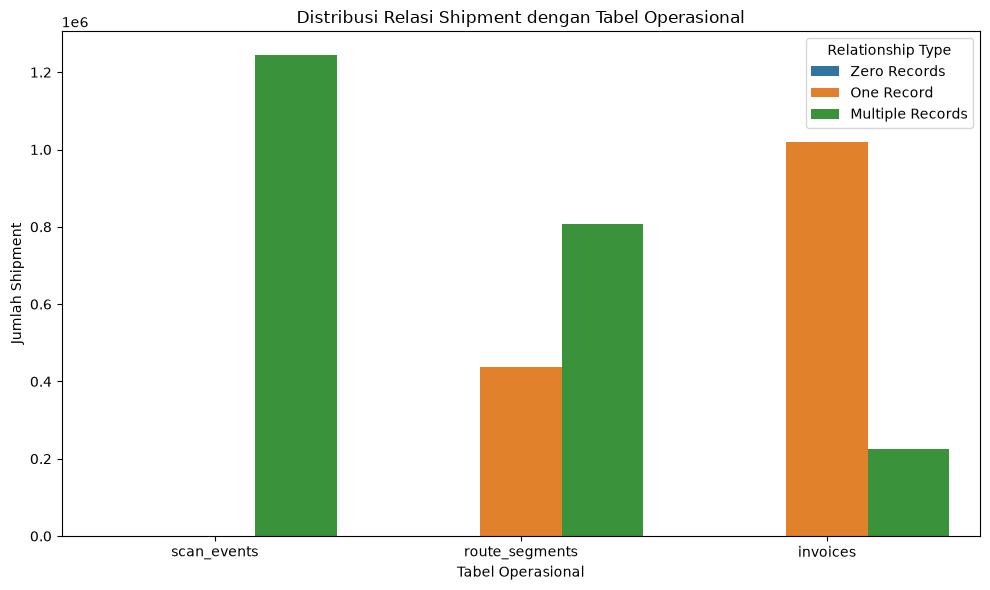

In [47]:
train_relationship = relationship_summary_df[
    relationship_summary_df["Split"] == "train"
]

fig, ax = plt.subplots(figsize=(10, 6))

relationship_plot = train_relationship.melt(
    id_vars="Operational Table",
    value_vars=[
        "Zero Records",
        "One Record",
        "Multiple Records"
    ],
    var_name="Relationship Type",
    value_name="Number of Shipments"
)

sns.barplot(
    data=relationship_plot,
    x="Operational Table",
    y="Number of Shipments",
    hue="Relationship Type",
    ax=ax
)

ax.set_title("Distribusi Relasi Shipment dengan Tabel Operasional")
ax.set_xlabel("Tabel Operasional")
ax.set_ylabel("Jumlah Shipment")

plt.tight_layout()
plt.show()

In [48]:
relationship_distribution_records = []

for split in SPLITS:
    for table in OPERATIONAL_TABLES:

        counts = relationship_count_cache[
            (split, table)
        ]

        shipment_ids = read_table(
            split,
            "shipments",
            ["shipment_id"]
        )

        coverage = (
            shipment_ids.join(
                counts,
                on="shipment_id",
                how="left"
            )
            .with_columns(
                pl.col("record_count").fill_null(0)
            )
        )

        distribution = (
            coverage.group_by("record_count")
            .len()
            .sort("record_count")
        )

        for row in distribution.iter_rows(named=True):

            relationship_distribution_records.append({
                "Split": split,
                "Operational Table": table,
                "Records per Shipment": row["record_count"],
                "Number of Shipments": row["len"]
            })

relationship_distribution_df = pd.DataFrame(
    relationship_distribution_records
)

display(relationship_distribution_df.head(30))

,Split,Operational Table,Records per Shipment,Number of Shipments
0,train,scan_events,2,37589
1,train,scan_events,3,130881
2,train,scan_events,4,231486
3,train,scan_events,5,268491
4,train,scan_events,6,234480
5,train,scan_events,7,163986
6,train,scan_events,8,95463
7,train,scan_events,9,48122
8,train,scan_events,10,20911
9,train,scan_events,11,8097


## 3.6 Transaction Frequency Distribution

Tahap ini bertujuan untuk memahami distribusi jumlah transaksi operasional pada setiap shipment.

Analisis berfokus pada tiga aktivitas utama:

1. Frekuensi scan events.
2. Jumlah route segments.
3. Jumlah invoices.

Distribusi frekuensi akan dianalisis untuk mengidentifikasi pola transaksi umum, variasi aktivitas, serta observasi dengan jumlah transaksi ekstrem.

Untuk dataset training, distribusi frekuensi juga akan dibandingkan berdasarkan masing-masing kelas status_penanganan.

Tujuannya adalah mengetahui apakah jumlah aktivitas operasional mempunyai hubungan dengan kondisi penanganan pengiriman.

Hasil analisis ini dapat digunakan untuk mengembangkan fitur agregasi seperti:

- Total jumlah scan.
- Jumlah segmen perjalanan.
- Jumlah invoice.
- Frekuensi aktivitas operasional.
- Deviasi jumlah aktivitas terhadap karakteristik umum shipment.

In [49]:
frequency_records = []
class_frequency_records = []

for table in OPERATIONAL_TABLES:

    for split in SPLITS:

        counts = relationship_count_cache[
            (split, table)
        ]

        shipment_columns = ["shipment_id"]

        if split == "train":
            shipment_columns.append("status_penanganan")

        shipments = read_table(
            split,
            "shipments",
            shipment_columns
        )

        coverage = (
            shipments.join(
                counts,
                on="shipment_id",
                how="left"
            )
            .with_columns(
                pl.col("record_count").fill_null(0)
            )
        )

        distribution = (
            coverage.group_by("record_count")
            .len()
            .sort("record_count")
        )

        for row in distribution.iter_rows(named=True):

            frequency_records.append({
                "Split": split,
                "Operational Table": table,
                "Records per Shipment": row["record_count"],
                "Number of Shipments": row["len"]
            })

        if split == "train":

            class_summary = (
                coverage.group_by("status_penanganan")
                .agg([
                    pl.len().alias("Shipments"),
                    pl.col("record_count").mean().alias("Mean Records"),
                    pl.col("record_count").median().alias("Median Records"),
                    pl.col("record_count").quantile(0.90).alias("P90 Records"),
                    pl.col("record_count").max().alias("Maximum Records")
                ])
            )

            for row in class_summary.iter_rows(named=True):

                class_frequency_records.append({
                    "Operational Table": table,
                    **row
                })

frequency_distribution_df = pd.DataFrame(
    frequency_records
)

class_frequency_df = pd.DataFrame(
    class_frequency_records
)

display(frequency_distribution_df)

,Split,Operational Table,Records per Shipment,Number of Shipments
0,train,scan_events,2,37589
1,train,scan_events,3,130881
2,train,scan_events,4,231486
3,train,scan_events,5,268491
4,train,scan_events,6,234480
5,train,scan_events,7,163986
6,train,scan_events,8,95463
7,train,scan_events,9,48122
8,train,scan_events,10,20911
9,train,scan_events,11,8097


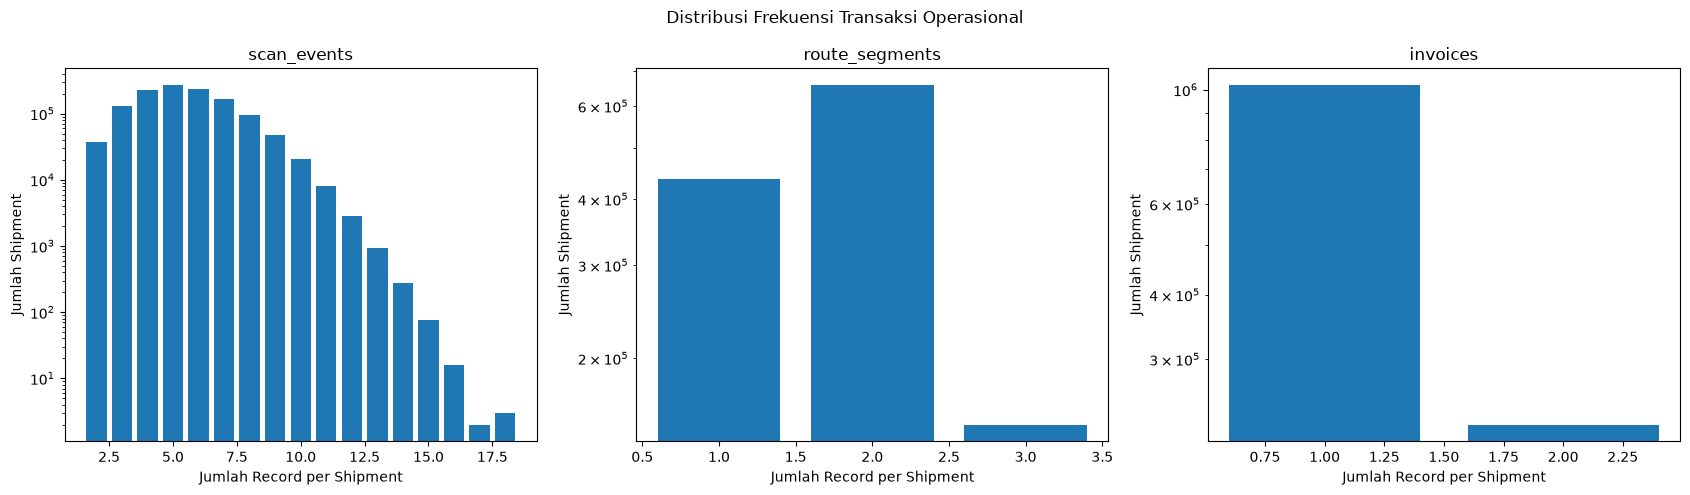

In [50]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for ax, table in zip(axes, OPERATIONAL_TABLES):

    data = frequency_distribution_df[
        (
            frequency_distribution_df["Split"] == "train"
        )
        &
        (
            frequency_distribution_df["Operational Table"] == table
        )
    ]

    ax.bar(
        data["Records per Shipment"],
        data["Number of Shipments"]
    )

    ax.set_title(table)
    ax.set_xlabel("Jumlah Record per Shipment")
    ax.set_ylabel("Jumlah Shipment")
    ax.set_yscale("log")

plt.suptitle(
    "Distribusi Frekuensi Transaksi Operasional"
)

plt.tight_layout()
plt.show()

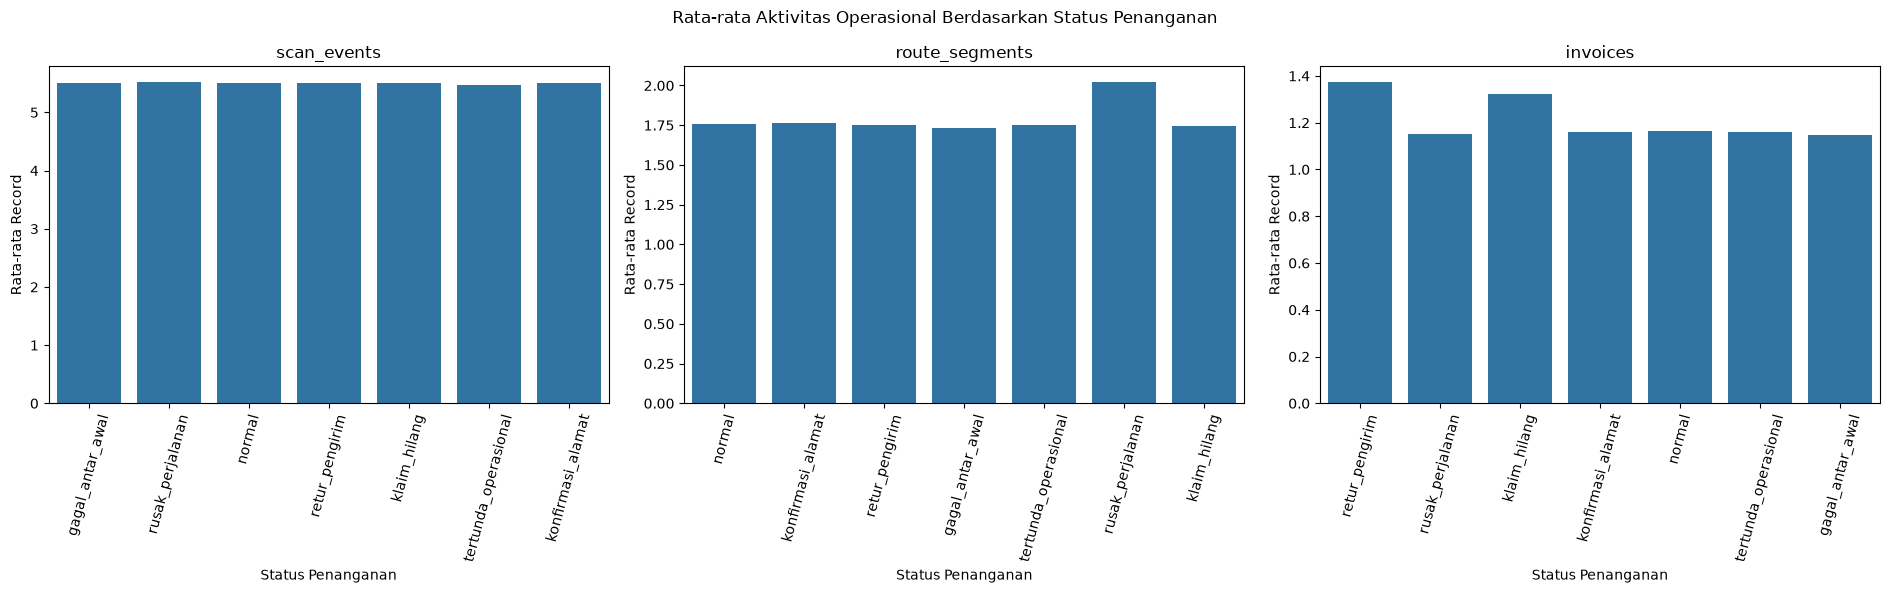

In [51]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 6)
)

for ax, table in zip(axes, OPERATIONAL_TABLES):

    data = class_frequency_df[
        class_frequency_df["Operational Table"] == table
    ]

    sns.barplot(
        data=data,
        x="status_penanganan",
        y="Mean Records",
        ax=ax
    )

    ax.set_title(table)
    ax.set_xlabel("Status Penanganan")
    ax.set_ylabel("Rata-rata Record")
    ax.tick_params(
        axis="x",
        rotation=75
    )

plt.suptitle(
    "Rata-rata Aktivitas Operasional Berdasarkan Status Penanganan"
)

plt.tight_layout()
plt.show()

In [52]:
class_frequency_pivot = class_frequency_df.pivot(
    index="status_penanganan",
    columns="Operational Table",
    values="Mean Records"
)

display(class_frequency_pivot)

Operational Table,invoices,route_segments,scan_events
status_penanganan,,,
gagal_antar_awal,1.149251,1.732582,5.511489
klaim_hilang,1.324145,1.745910,5.505895
konfirmasi_alamat,1.161884,1.765708,5.504062
normal,1.162619,1.759017,5.497587
retur_pengirim,1.372373,1.753385,5.499476
rusak_perjalanan,1.152239,2.019438,5.515902
tertunda_operasional,1.162020,1.753208,5.471223


## 3.7 Missingness Pattern Analysis

Missingness pattern analysis dilakukan untuk memahami karakteristik dan kemungkinan penyebab nilai kosong pada dataset.

Analisis ini merupakan kelanjutan dari temuan pada Section 02.

Fitur yang menjadi perhatian utama:

1. shipments.volume_l
2. invoices.discount
3. route_segments.durasi_jam
4. customers.credit_score
5. couriers.courier_score

Analisis dilakukan melalui beberapa pendekatan:

- Perbandingan missing values antara training dan testing.
- Identifikasi kelompok kategori yang mempunyai missing values tinggi.
- Pengukuran persentase missing values berdasarkan jenis transaksi.
- Analisis missing values terhadap target training.
- Identifikasi kemungkinan hubungan missingness dengan kondisi operasional.

Tujuannya adalah mengetahui apakah nilai kosong terjadi secara acak atau berkaitan dengan karakteristik tertentu.

Hasil analisis akan digunakan untuk menentukan strategi imputasi dan kemungkinan pembuatan missing indicator pada tahap preprocessing.

In [53]:
MISSING_FEATURES = {
    "shipments": ["volume_l"],
    "invoices": ["discount"],
    "route_segments": ["durasi_jam"],
    "customers": ["credit_score"],
    "couriers": ["courier_score"]
}

missingness_records = []

for split in SPLITS:

    for table, features in MISSING_FEATURES.items():

        for feature in features:

            df = read_table(
                split,
                table,
                [feature]
            )

            total_rows = df.height
            missing_count = df[feature].null_count()

            missingness_records.append({
                "Split": split,
                "Table": table,
                "Feature": feature,
                "Total Records": total_rows,
                "Missing Records": missing_count,
                "Non-Missing Records": (
                    total_rows - missing_count
                ),
                "Missing Percentage": (
                    missing_count / total_rows * 100
                    if total_rows > 0 else 0
                )
            })

missingness_summary_df = pd.DataFrame(
    missingness_records
)

display(missingness_summary_df)

,Split,Table,Feature,Total Records,Missing Records,Non-Missing Records,Missing Percentage
0,train,shipments,volume_l,1243617,37012,1206605,2.976157
1,train,invoices,discount,1467722,622355,845367,42.402785
2,train,route_segments,durasi_jam,2200148,43968,2156180,1.998411
3,train,customers,credit_score,573841,11429,562412,1.991667
4,train,couriers,courier_score,23806,256,23550,1.075359
5,test,shipments,volume_l,362245,11013,351232,3.040208
6,test,invoices,discount,427458,181088,246370,42.363928
7,test,route_segments,durasi_jam,641446,12824,628622,1.999233
8,test,customers,credit_score,573841,11429,562412,1.991667
9,test,couriers,courier_score,23806,256,23550,1.075359


In [54]:
missingness_comparison_df = missingness_summary_df.pivot(
    index=["Table", "Feature"],
    columns="Split",
    values="Missing Percentage"
).reset_index()

missingness_comparison_df["Difference"] = (
    missingness_comparison_df["train"]
    - missingness_comparison_df["test"]
)

display(missingness_comparison_df)

Split,Table,Feature,test,train,Difference
0,couriers,courier_score,1.075359,1.075359,0.000000
1,customers,credit_score,1.991667,1.991667,0.000000
2,invoices,discount,42.363928,42.402785,0.038857
3,route_segments,durasi_jam,1.999233,1.998411,-0.000822
4,shipments,volume_l,3.040208,2.976157,-0.064050


In [55]:
def grouped_missing_rate(df, feature, group_columns, feature_name):

    result = (
        df.group_by(group_columns)
        .agg([
            pl.len().alias("Total Records"),
            pl.col(feature).null_count().alias("Missing Records")
        ])
        .with_columns(
            (
                pl.col("Missing Records")
                / pl.col("Total Records")
                * 100
            ).alias("Missing Percentage")
        )
        .sort(
            "Missing Percentage",
            descending=True
        )
    )

    output = result.to_pandas()

    output.insert(
        0,
        "Feature",
        feature_name
    )

    return output

In [56]:
train_shipments_missing = read_table(
    "train",
    "shipments",
    [
        "shipment_id",
        "status_penanganan",
        "volume_l"
    ]
)

missing_volume_by_class = grouped_missing_rate(
    train_shipments_missing,
    "volume_l",
    ["status_penanganan"],
    "shipments.volume_l"
)

print(missing_volume_by_class)

              Feature     status_penanganan  Total Records  Missing Records  \
0  shipments.volume_l     konfirmasi_alamat         272911             8275   
1  shipments.volume_l  tertunda_operasional         185496             5559   
2  shipments.volume_l      gagal_antar_awal         124341             3717   
3  shipments.volume_l      rusak_perjalanan          61942             1843   
4  shipments.volume_l                normal         473531            13954   
5  shipments.volume_l        retur_pengirim          87740             2575   
6  shipments.volume_l          klaim_hilang          37656             1089   

   Missing Percentage  
0            3.032124  
1            2.996830  
2            2.989360  
3            2.975364  
4            2.946798  
5            2.934807  
6            2.891969  


In [57]:
train_shipment_targets = read_table(
    "train",
    "shipments",
    [
        "shipment_id",
        "status_penanganan"
    ]
)

train_invoices = read_table(
    "train",
    "invoices",
    [
        "shipment_id",
        "invoice_type",
        "payment_status",
        "discount"
    ]
)

invoice_missing_data = train_invoices.join(
    train_shipment_targets,
    on="shipment_id",
    how="left"
)

invoice_missing_analysis = grouped_missing_rate(
    invoice_missing_data,
    "discount",
    [
        "status_penanganan",
        "invoice_type",
        "payment_status"
    ],
    "invoices.discount"
)

display(invoice_missing_analysis)

,Feature,status_penanganan,invoice_type,payment_status,Total Records,Missing Records,Missing Percentage
0,invoices.discount,normal,langganan,lunas,227279,227279,100.0
1,invoices.discount,rusak_perjalanan,langganan,tertunda,1291,1291,100.0
2,invoices.discount,retur_pengirim,langganan,gagal,43,43,100.0
3,invoices.discount,rusak_perjalanan,langganan,lunas,29546,29546,100.0
4,invoices.discount,klaim_hilang,langganan,tertunda,762,762,100.0
...,...,...,...,...,...,...,...
58,invoices.discount,rusak_perjalanan,klaim,tertunda,418,0,0.0
59,invoices.discount,rusak_perjalanan,klaim,lunas,9003,0,0.0
60,invoices.discount,retur_pengirim,klaim,tertunda,1341,0,0.0
61,invoices.discount,rusak_perjalanan,pengiriman,lunas,29809,0,0.0


In [58]:
train_routes = read_table(
    "train",
    "route_segments",
    [
        "shipment_id",
        "moda",
        "durasi_jam"
    ]
)

route_missing_data = train_routes.join(
    train_shipment_targets,
    on="shipment_id",
    how="left"
)

route_missing_analysis = grouped_missing_rate(
    route_missing_data,
    "durasi_jam",
    [
        "status_penanganan",
        "moda"
    ],
    "route_segments.durasi_jam"
)

display(route_missing_analysis)

,Feature,status_penanganan,moda,Total Records,Missing Records,Missing Percentage
0,route_segments.durasi_jam,rusak_perjalanan,laut,16708,371,2.220493
1,route_segments.durasi_jam,klaim_hilang,darat,41209,893,2.167002
2,route_segments.durasi_jam,gagal_antar_awal,laut,29251,628,2.146935
3,route_segments.durasi_jam,retur_pengirim,darat,96873,2020,2.085204
4,route_segments.durasi_jam,klaim_hilang,laut,9017,188,2.084951
5,route_segments.durasi_jam,retur_pengirim,laut,20974,435,2.073996
6,route_segments.durasi_jam,normal,udara,112888,2311,2.047162
7,route_segments.durasi_jam,normal,laut,114853,2340,2.037387
8,route_segments.durasi_jam,konfirmasi_alamat,laut,66931,1360,2.031943
9,route_segments.durasi_jam,klaim_hilang,kereta,6976,141,2.021216


In [59]:
train_customers = read_table(
    "train",
    "customers",
    [
        "customer_id",
        "segment",
        "credit_score"
    ]
)

train_shipments_customer = read_table(
    "train",
    "shipments",
    [
        "customer_id",
        "status_penanganan"
    ]
)

customer_missing_data = train_shipments_customer.join(
    train_customers,
    on="customer_id",
    how="left"
)

customer_missing_analysis = grouped_missing_rate(
    customer_missing_data,
    "credit_score",
    [
        "status_penanganan",
        "segment"
    ],
    "customers.credit_score"
)

display(customer_missing_analysis)

,Feature,status_penanganan,segment,Total Records,Missing Records,Missing Percentage
0,customers.credit_score,retur_pengirim,korporat,11347,263,2.317793
1,customers.credit_score,klaim_hilang,korporat,5003,114,2.278633
2,customers.credit_score,klaim_hilang,institusi,2701,58,2.147353
3,customers.credit_score,klaim_hilang,umkm,9464,202,2.134404
4,customers.credit_score,gagal_antar_awal,korporat,16097,335,2.081133
5,customers.credit_score,retur_pengirim,umkm,22200,461,2.076577
6,customers.credit_score,retur_pengirim,retail,48011,995,2.072442
7,customers.credit_score,tertunda_operasional,institusi,13034,268,2.056161
8,customers.credit_score,normal,institusi,32713,671,2.051172
9,customers.credit_score,normal,korporat,61838,1263,2.042433


In [60]:
train_couriers = read_table(
    "train",
    "couriers",
    [
        "courier_id",
        "vehicle_type",
        "courier_score"
    ]
)

train_shipments_courier = read_table(
    "train",
    "shipments",
    [
        "courier_id",
        "status_penanganan"
    ]
)

courier_missing_data = train_shipments_courier.join(
    train_couriers,
    on="courier_id",
    how="left"
)

courier_missing_analysis = grouped_missing_rate(
    courier_missing_data,
    "courier_score",
    [
        "status_penanganan",
        "vehicle_type"
    ],
    "couriers.courier_score"
)

display(courier_missing_analysis)

,Feature,status_penanganan,vehicle_type,Total Records,Missing Records,Missing Percentage
0,couriers.courier_score,klaim_hilang,truk_besar,3142,59,1.877785
1,couriers.courier_score,rusak_perjalanan,truk_besar,5084,85,1.671912
2,couriers.courier_score,gagal_antar_awal,truk_besar,10071,153,1.519214
3,couriers.courier_score,klaim_hilang,truk_kecil,5993,83,1.384949
4,couriers.courier_score,retur_pengirim,truk_besar,7152,99,1.384228
5,couriers.courier_score,normal,truk_kecil,76307,998,1.307875
6,couriers.courier_score,tertunda_operasional,truk_kecil,29864,380,1.272435
7,couriers.courier_score,gagal_antar_awal,mobil_van,37063,458,1.235734
8,couriers.courier_score,klaim_hilang,mobil_van,11112,134,1.205904
9,couriers.courier_score,konfirmasi_alamat,truk_kecil,43644,510,1.168546


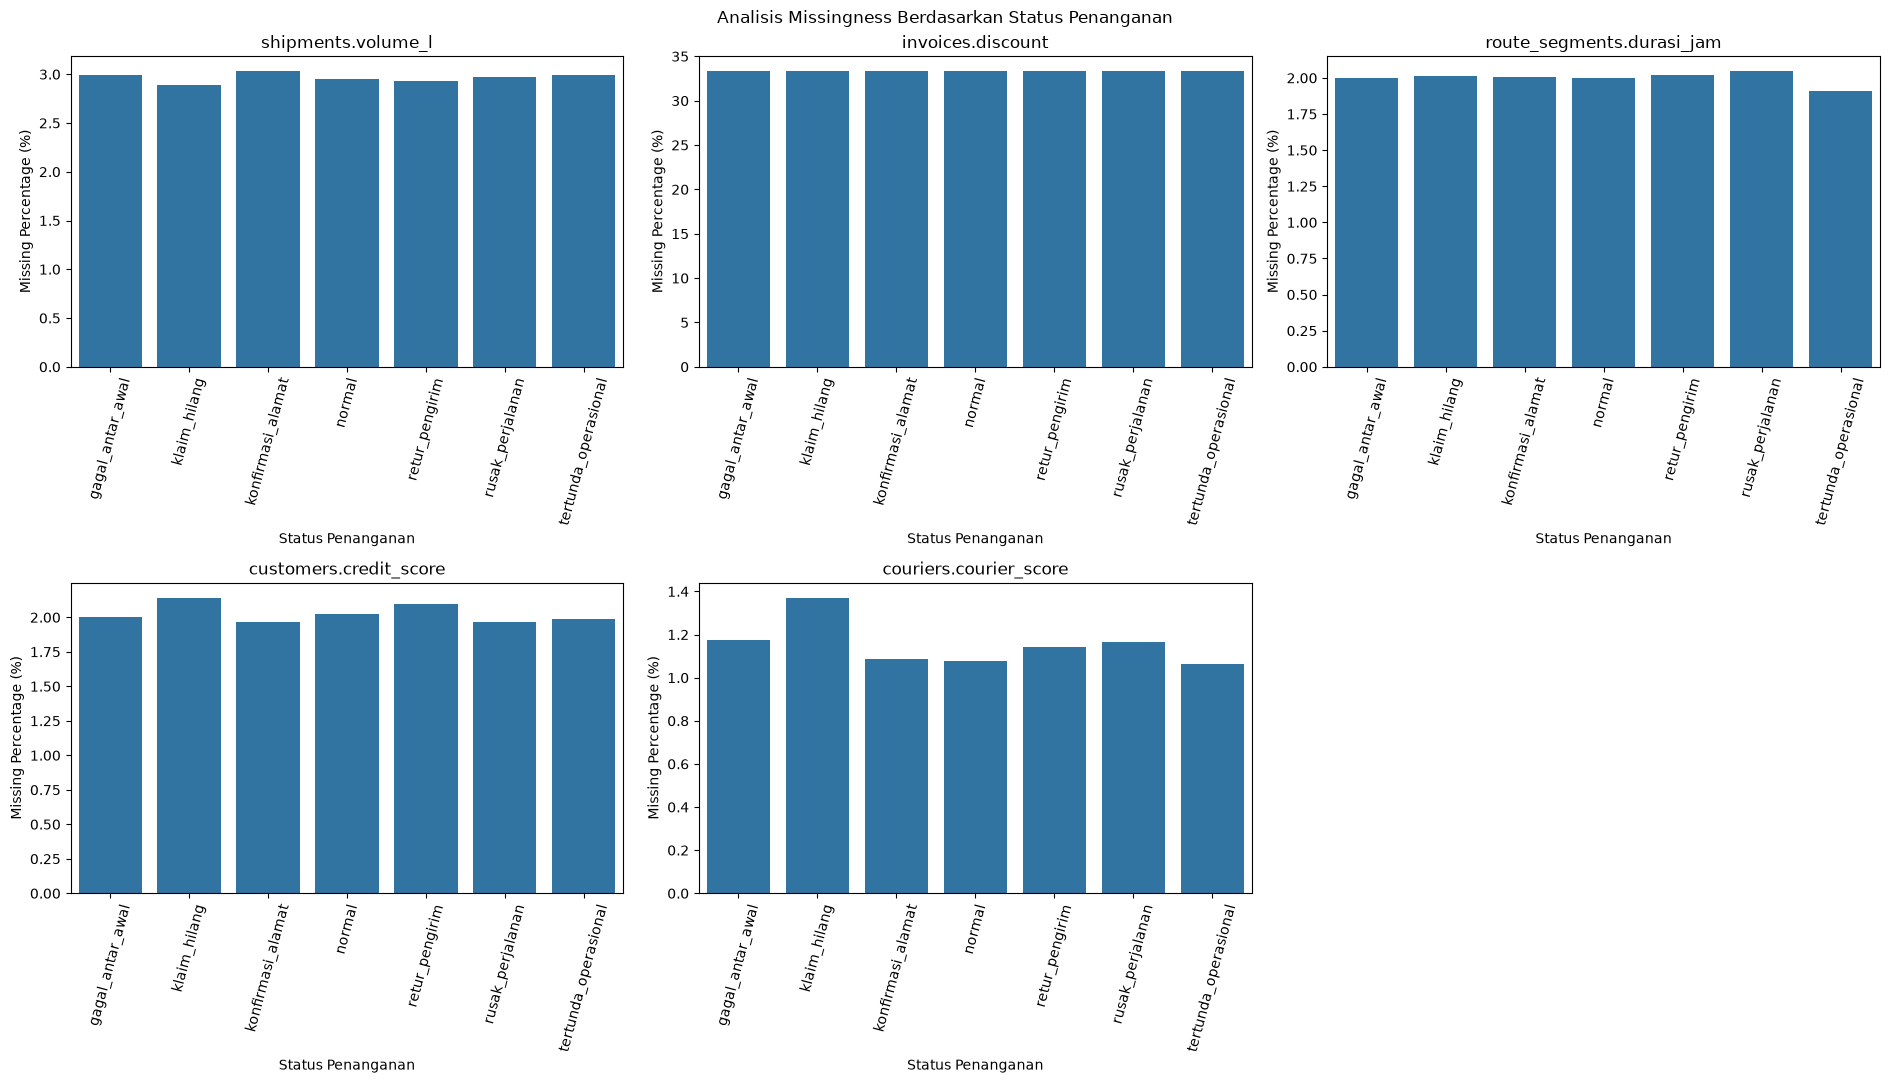

In [61]:
missingness_by_class = pd.concat(
    [
        missing_volume_by_class,
        invoice_missing_analysis,
        route_missing_analysis,
        customer_missing_analysis,
        courier_missing_analysis
    ],
    ignore_index=True,
    sort=False
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(19, 11)
)

missing_features_list = [
    (
        "shipments.volume_l",
        missing_volume_by_class,
        "status_penanganan"
    ),
    (
        "invoices.discount",
        invoice_missing_analysis,
        "status_penanganan"
    ),
    (
        "route_segments.durasi_jam",
        route_missing_analysis,
        "status_penanganan"
    ),
    (
        "customers.credit_score",
        customer_missing_analysis,
        "status_penanganan"
    ),
    (
        "couriers.courier_score",
        courier_missing_analysis,
        "status_penanganan"
    )
]

for ax, (feature, data, x_column) in zip(
    axes.flatten(),
    missing_features_list
):

    plot_data = (
        data.groupby(x_column)["Missing Percentage"]
        .mean()
        .reset_index()
    )

    sns.barplot(
        data=plot_data,
        x=x_column,
        y="Missing Percentage",
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Status Penanganan")
    ax.set_ylabel("Missing Percentage (%)")
    ax.tick_params(
        axis="x",
        rotation=75
    )

axes.flatten()[-1].set_visible(False)

plt.suptitle(
    "Analisis Missingness Berdasarkan Status Penanganan"
)

plt.tight_layout()
plt.show()

## 3.8 Data Quality Findings

Tahap terakhir bertujuan untuk merangkum hasil pemeriksaan kualitas data dan integritas relasional.

Temuan dikelompokkan berdasarkan:

1. Validitas primary key.
2. Duplikasi record.
3. Integritas foreign key.
4. Orphan records.
5. Kelengkapan relasi one-to-many.
6. Pola missing values.

Setiap temuan akan dievaluasi berdasarkan jumlah observasi yang terdampak dan kemungkinan pengaruhnya terhadap proses preprocessing serta feature engineering.

Rekomendasi perbaikan akan ditentukan berdasarkan hasil pemeriksaan aktual, bukan asumsi awal.

Hasil akhir akan menjadi acuan dalam menentukan apakah data dapat langsung diintegrasikan atau membutuhkan penanganan khusus.

In [62]:
findings = []

for _, row in primary_key_df.iterrows():

    if row["Null Key Rows"] > 0:

        findings.append({
            "Category": "Primary Key",
            "Table": row["Table"],
            "Finding": f"Identifier kosong pada {row['Key Columns']}",
            "Affected Records": row["Null Key Rows"],
            "Status": "Perlu Investigasi",
            "Recommendation": "Periksa kelengkapan identifier"
        })

    if row["Duplicate Excess"] > 0:

        findings.append({
            "Category": "Primary Key",
            "Table": row["Table"],
            "Finding": f"Identifier duplikat pada {row['Key Columns']}",
            "Affected Records": row["Duplicate Excess"],
            "Status": "Perlu Investigasi",
            "Recommendation": "Periksa record yang menggunakan identifier sama"
        })

for _, row in duplicate_records_df.iterrows():

    if row["Duplicate Excess"] > 0:

        findings.append({
            "Category": "Duplicate Records",
            "Table": row["Table"],
            "Finding": "Ditemukan duplikasi seluruh kolom",
            "Affected Records": row["Duplicate Excess"],
            "Status": "Perlu Investigasi",
            "Recommendation": "Periksa apakah duplikasi merupakan kesalahan pencatatan"
        })

for _, row in foreign_key_df.iterrows():

    if row["Null References"] > 0:

        findings.append({
            "Category": "Foreign Key",
            "Table": row["Child Table"],
            "Finding": f"Foreign key kosong pada {row['Foreign Key']}",
            "Affected Records": row["Null References"],
            "Status": "Perlu Investigasi",
            "Recommendation": "Evaluasi kelengkapan relasi antarentitas"
        })

    if row["Orphan Rows"] > 0:

        findings.append({
            "Category": "Foreign Key",
            "Table": row["Child Table"],
            "Finding": f"Referensi tidak ditemukan pada {row['Parent Table']}",
            "Affected Records": row["Orphan Rows"],
            "Status": "Perlu Investigasi",
            "Recommendation": "Validasi identifier dan sumber relasi"
        })

for _, row in relationship_summary_df.iterrows():

    if row["Zero Records"] > 0:

        findings.append({
            "Category": "Relationship",
            "Table": row["Operational Table"],
            "Finding": "Shipment tidak memiliki record operasional",
            "Affected Records": row["Zero Records"],
            "Status": "Perlu Investigasi",
            "Recommendation": "Periksa kelengkapan data operasional"
        })

for _, row in missingness_summary_df.iterrows():

    if row["Missing Records"] > 0:

        status = (
            "Prioritas Tinggi"
            if row["Missing Percentage"] >= 20
            else "Perlu Evaluasi"
        )

        findings.append({
            "Category": "Missing Values",
            "Table": row["Table"],
            "Finding": f"Missing values pada {row['Feature']}",
            "Affected Records": row["Missing Records"],
            "Status": status,
            "Recommendation": "Analisis pola missingness sebelum menentukan imputasi"
        })

data_quality_findings_df = pd.DataFrame(findings)

if data_quality_findings_df.empty:
    print("Tidak ditemukan masalah kualitas data berdasarkan pemeriksaan.")
else:
    display(
        data_quality_findings_df.sort_values(
            "Affected Records",
            ascending=False
        ).reset_index(drop=True)
    )

,Category,Table,Finding,Affected Records,Status,Recommendation
0,Foreign Key,shipments,Referensi tidak ditemukan pada promotions,1032408,Perlu Investigasi,Validasi identifier dan sumber relasi
1,Missing Values,invoices,Missing values pada discount,622355,Prioritas Tinggi,Analisis pola missingness sebelum menentukan i...
2,Foreign Key,shipments,Referensi tidak ditemukan pada promotions,300502,Perlu Investigasi,Validasi identifier dan sumber relasi
3,Missing Values,invoices,Missing values pada discount,181088,Prioritas Tinggi,Analisis pola missingness sebelum menentukan i...
4,Missing Values,route_segments,Missing values pada durasi_jam,43968,Perlu Evaluasi,Analisis pola missingness sebelum menentukan i...
5,Missing Values,shipments,Missing values pada volume_l,37012,Perlu Evaluasi,Analisis pola missingness sebelum menentukan i...
6,Missing Values,route_segments,Missing values pada durasi_jam,12824,Perlu Evaluasi,Analisis pola missingness sebelum menentukan i...
7,Missing Values,customers,Missing values pada credit_score,11429,Perlu Evaluasi,Analisis pola missingness sebelum menentukan i...
8,Missing Values,customers,Missing values pada credit_score,11429,Perlu Evaluasi,Analisis pola missingness sebelum menentukan i...
9,Missing Values,shipments,Missing values pada volume_l,11013,Perlu Evaluasi,Analisis pola missingness sebelum menentukan i...


In [63]:
quality_summary = pd.DataFrame([
    {
        "Analysis": "Primary Key Validation",
        "Total Checks": len(primary_key_df),
        "Passed": int(primary_key_df["Valid"].sum()),
        "Failed": int((~primary_key_df["Valid"]).sum())
    },
    {
        "Analysis": "Foreign Key Integrity",
        "Total Checks": len(foreign_key_df),
        "Passed": int(foreign_key_df["Valid"].sum()),
        "Failed": int((~foreign_key_df["Valid"]).sum())
    },
    {
        "Analysis": "Full Row Duplicate Detection",
        "Total Checks": len(duplicate_records_df),
        "Passed": int(
            (duplicate_records_df["Duplicate Excess"] == 0).sum()
        ),
        "Failed": int(
            (duplicate_records_df["Duplicate Excess"] > 0).sum()
        )
    },
    {
        "Analysis": "One-to-Many Coverage",
        "Total Checks": len(relationship_summary_df),
        "Passed": int(
            (relationship_summary_df["Zero Records"] == 0).sum()
        ),
        "Failed": int(
            (relationship_summary_df["Zero Records"] > 0).sum()
        )
    }
])

display(quality_summary)

,Analysis,Total Checks,Passed,Failed
0,Primary Key Validation,20,20,0
1,Foreign Key Integrity,24,22,2
2,Full Row Duplicate Detection,18,18,0
3,One-to-Many Coverage,6,6,0


In [64]:
OUTPUTS = {
    "primary_key_validation.csv": primary_key_df,
    "primary_key_summary.csv": primary_key_summary,
    "duplicate_records.csv": duplicate_records_df,
    "identifier_duplicates.csv": identifier_duplicates_df,
    "foreign_key_integrity.csv": foreign_key_df,
    "foreign_key_summary.csv": foreign_key_summary,
    "orphan_records.csv": orphan_df,
    "relationship_summary.csv": relationship_summary_df,
    "relationship_distribution.csv": relationship_distribution_df,
    "frequency_distribution.csv": frequency_distribution_df,
    "class_frequency_analysis.csv": class_frequency_df,
    "missingness_summary.csv": missingness_summary_df,
    "missingness_comparison.csv": missingness_comparison_df,
    "missingness_pattern.csv": missingness_by_class,
    "data_quality_findings.csv": data_quality_findings_df,
    "quality_summary.csv": quality_summary
}

for filename, dataframe in OUTPUTS.items():

    dataframe.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("Section 03 analysis completed.")
print("Total output files:", len(OUTPUTS))
print("Output directory:", OUTPUT_DIR.resolve())

Section 03 analysis completed.
Total output files: 16
Output directory: C:\Users\ASUS\.vscode\arkavidia\eda_outputs
